# Phase 7 - Tree models

Code: `src/models/trees.py`. This notebook shows:
1. what a decision tree actually learns (readable rules!)
2. why one tree **overfits** and how depth controls it
3. how **boosting** builds a strong model from many weak trees
4. what the best model pays attention to, and the "it depends" patterns it found
5. how to explain a single prediction

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))
from src.evaluate import load_data, get_split, score
from src.features import FEATURES
from src.models.trees import TreeCore, BoostingCore, LightGBM

BLUE, ORANGE, AQUA, YELLOW, INK, INK_2 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": "#e8e7e2", "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110,
})

df = load_data()
train, valid = get_split(df, "valid")
medians = train[FEATURES].median()
X_train = train[FEATURES].fillna(medians).to_numpy(float)
X_valid = valid[FEATURES].fillna(medians).to_numpy(float)
y_train, y_valid = train["PTS"].to_numpy(float), valid["PTS"].to_numpy(float)

## 1. A tiny tree you can read

A depth-3 tree: at most 3 yes/no questions, ending in 8 "leaves". Each leaf predicts the **average** of the training games that land there.
The tree chose these questions itself, by trying every feature and every cut-off and keeping whichever split reduced the error most.

In [2]:
tiny = TreeCore(max_depth=3, min_samples_leaf=100).fit(X_train, y_train)
print(tiny.rules(FEATURES))
print(f"Validation MAE of this 8-leaf tree: {np.mean(np.abs(tiny.predict(X_valid) - y_valid)):.3f}")

PTS_EWM20 <= 13.19?
  yes:
    TEAM_PTS_RANK <= 6.50?
      yes:
        PTS_EWM20 <= 9.62?
          yes:
            -> predict 8.9
          no:
            -> predict 11.4
      no:
        PTS_EWM10 <= 5.69?
          yes:
            -> predict 4.1
          no:
            -> predict 7.1
  no:
    PTS_EWM20 <= 20.63?
      yes:
        PTS_EWM20 <= 16.77?
          yes:
            -> predict 14.8
          no:
            -> predict 18.6
      no:
        PTS_EWM20 <= 25.79?
          yes:
            -> predict 22.7
          no:
            -> predict 28.1

Validation MAE of this 8-leaf tree: 4.740


**Read it like a flowchart.** It first splits on a scoring average (the most useful single question), then refines with more questions.
With only 8 possible outputs it's crude - but it already beats the "last 3 games" baseline.

## 2. Deeper trees: more detail, then overfitting

A deeper tree asks more questions and fits the training data more closely. But at some point it starts memorizing **noise**
(random lucky nights in the training data) instead of real patterns. That's **overfitting**: training error keeps falling,
validation error stops improving and gets worse.

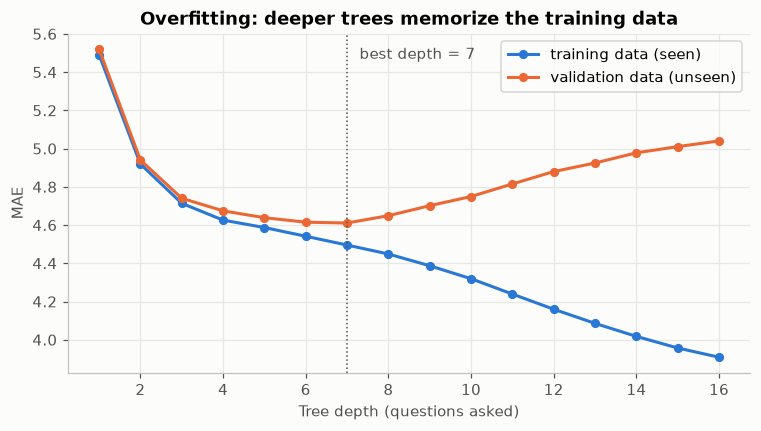

In [3]:
depths = range(1, 17)
train_mae, valid_mae = [], []
for d in depths:
    t = TreeCore(max_depth=d, min_samples_leaf=20).fit(X_train, y_train)
    train_mae.append(np.mean(np.abs(t.predict(X_train) - y_train)))
    valid_mae.append(np.mean(np.abs(t.predict(X_valid) - y_valid)))

best = int(np.argmin(valid_mae))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, train_mae, "o-", color=BLUE, linewidth=2, markersize=5, label="training data (seen)")
ax.plot(depths, valid_mae, "o-", color=ORANGE, linewidth=2, markersize=5, label="validation data (unseen)")
ax.axvline(depths[best], color=INK_2, linestyle=":", linewidth=1)
ax.text(depths[best] + 0.3, max(valid_mae) - 0.05, f"best depth = {depths[best]}", color=INK_2)
ax.set(title="Overfitting: deeper trees memorize the training data", xlabel="Tree depth (questions asked)", ylabel="MAE")
ax.legend()
plt.show()

**What this tells us:** the two lines split apart. By depth 16 the tree has ~thousands of leaves and is "great" on training games
it has already seen, but worse on new games. **The gap between the lines = overfitting.**
That's why every model in this project is judged only on data it never trained on.

## 3. Boosting: many small trees, each fixing the last one's mistakes

Our from-scratch booster (`BoostingCore`):
1. Start by predicting the average for everyone.
2. Compute the **residuals** (actual - prediction): what we still get wrong.
3. Fit a small depth-4 tree to the residuals.
4. Add 10% of its output (the **learning rate**) to the prediction.
5. Repeat.

This takes about a minute to run.

trained 150 trees in 59s


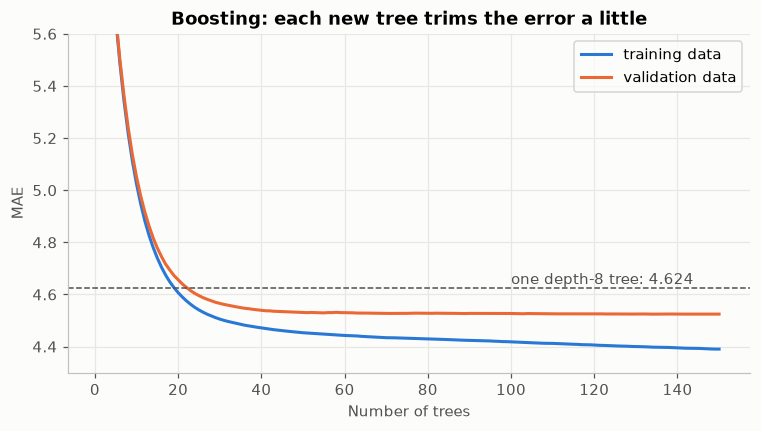

After 150 small trees: validation MAE 4.525


In [4]:
start = time.time()
booster = BoostingCore(n_rounds=150, learning_rate=0.1, max_depth=4, min_samples_leaf=200).fit(X_train, y_train)
print(f"trained 150 trees in {time.time() - start:.0f}s")

staged_valid = [np.mean(np.abs(p - y_valid)) for p in booster.staged_predict(X_valid)]
staged_train = [np.mean(np.abs(p - y_train)) for p in booster.staged_predict(X_train)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 151), staged_train, color=BLUE, linewidth=2, label="training data")
ax.plot(range(1, 151), staged_valid, color=ORANGE, linewidth=2, label="validation data")
ax.axhline(4.624, color=INK_2, linestyle="--", linewidth=1)
ax.text(100, 4.64, "one depth-8 tree: 4.624", color=INK_2)
ax.set(title="Boosting: each new tree trims the error a little", xlabel="Number of trees", ylabel="MAE", ylim=(4.3, 5.6))
ax.legend()
plt.show()
print(f"After 150 small trees: validation MAE {staged_valid[-1]:.3f}")

**What this tells us:** 150 small, simple trees (4.52) beat one big tree (4.62) by a lot. Each tree alone is weak,
but each one focuses on the mistakes left over by the others. That idea - **boosting** - powers most winning models on table data.

**LightGBM** is the same idea, engineered to be ~30x faster, with extras: it handles blanks (NaN) itself, picks the number of trees
automatically with **early stopping**, and can optimize **absolute error** directly (our MAE scoreboard).

## 4. What does LightGBM pay attention to?

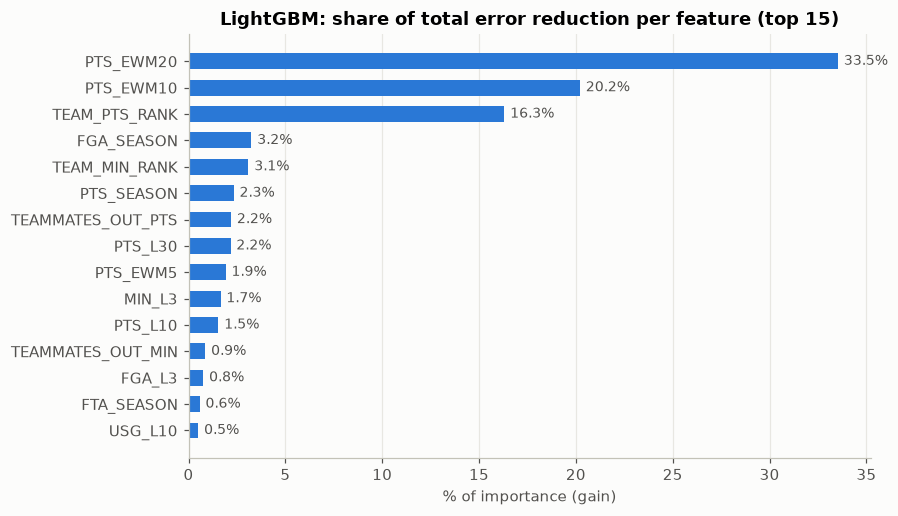

In [5]:
lgbm = LightGBM("regression_l1").fit(train)
imp = lgbm.importance().head(15)[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values * 100, color=BLUE, height=0.6)
for i, v in enumerate(imp.values * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", color=INK_2, fontsize=9)
ax.set(title="LightGBM: share of total error reduction per feature (top 15)", xlabel="% of importance (gain)")
ax.grid(axis="y", visible=False)
plt.show()

**What this tells us:**
- The **weighted scoring averages** (`PTS_EWM20`, `PTS_EWM10`) do over half the work - no surprise.
- **#3 is role:** `TEAM_PTS_RANK` = "is he his team's 1st scoring option tonight, or the 8th?" (out of the players actually playing).
  Notice it also quietly captures teammates-out: if the #1 scorer sits, everyone moves up a rank.
- `TEAMMATES_OUT_PTS` and minutes features follow with a few % each.
- **Opponent features (defense, pace) don't even make the top 15.** Matches what we saw in Phase 1: the opponent matters, but only a little.

## 5. "It depends" - patterns the trees found on their own

How does the model's prediction change as **teammates-out** goes up? We take real games, set `TEAMMATES_OUT_PTS` to 0, 5, 10... for all of them,
and average the predictions (a **partial dependence** plot). Done separately for stars and bench players.

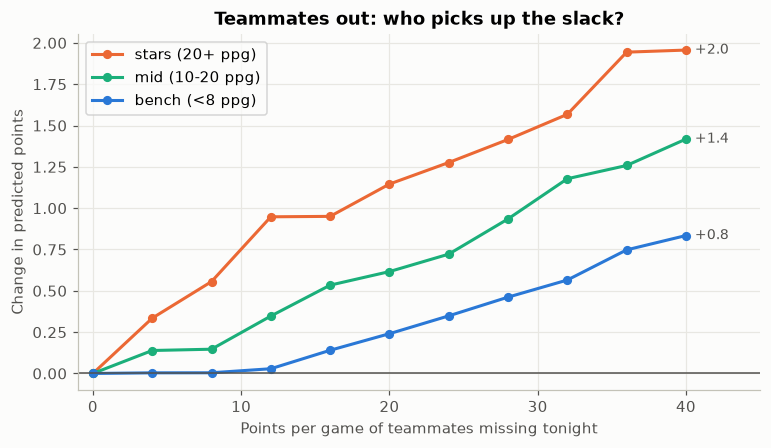

In [6]:
lgbm_l2 = LightGBM("regression").fit(train)   # squared-error version: predicts the average, easier to read here
grid = np.arange(0, 41, 4)

def partial_dependence(model, rows, feature, grid):
    out = []
    for v in grid:
        changed = rows.copy()
        changed[feature] = v
        out.append(model.predict(changed).mean())
    return np.array(out) - out[0]                  # change vs "nobody missing"

stars = valid[valid["PTS_EWM20"] >= 20].sample(1500, random_state=0)
mids = valid[valid["PTS_EWM20"].between(10, 20)].sample(1500, random_state=0)
bench = valid[valid["PTS_EWM20"] < 8].sample(1500, random_state=0)

fig, ax = plt.subplots(figsize=(8, 4.2))
for rows, color, label in [(stars, ORANGE, "stars (20+ ppg)"), (mids, AQUA, "mid (10-20 ppg)"), (bench, BLUE, "bench (<8 ppg)")]:
    pd_vals = partial_dependence(lgbm_l2, rows, "TEAMMATES_OUT_PTS", grid)
    ax.plot(grid, pd_vals, "o-", color=color, linewidth=2, markersize=5, label=label)
    ax.text(grid[-1] + 0.6, pd_vals[-1], f"{pd_vals[-1]:+.1f}", va="center", color=INK_2, fontsize=9)
ax.axhline(0, color=INK_2, linewidth=1)
ax.set(title="Teammates out: who picks up the slack?", xlabel="Points per game of teammates missing tonight",
       ylabel="Change in predicted points", xlim=(-1, 45))
ax.legend(loc="upper left")
plt.show()

**What this tells us:** when teammates are missing, **everyone's** prediction rises, but stars and mid-level players gain more points than bench players.
The tree model discovered that "it depends on who you are" by itself - no hand-made interaction feature needed.

## 6. Explaining one prediction

LightGBM can split any single prediction into **contributions** per feature (these are called **SHAP values**):
`prediction = average + contribution 1 + contribution 2 + ...`

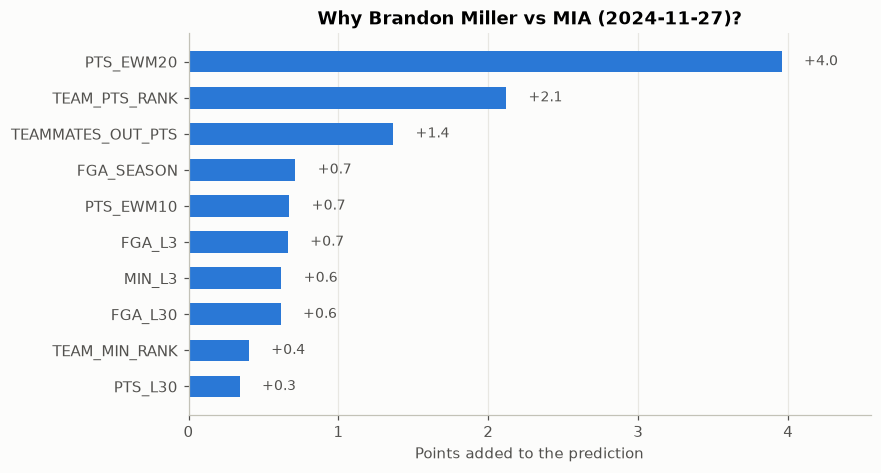

average player-game: 10.9  +  all contributions: +12.0  =  prediction 22.9   (actual: 21)
Teammates out that night: 47.2 ppg worth


In [7]:
# Pick a star game with many teammates out, where that feature clearly mattered.
candidates = valid[(valid["PTS_EWM20"] > 20) & (valid["TEAMMATES_OUT_PTS"] > 20)]
c_all = lgbm_l2.booster.predict(candidates[FEATURES], pred_contrib=True)
out_col = FEATURES.index("TEAMMATES_OUT_PTS")
pick = np.argsort(c_all[:, out_col])[int(0.9 * len(candidates))]
row = candidates.iloc[[pick]]
contrib = c_all[pick]
base, parts = contrib[-1], pd.Series(contrib[:-1], index=FEATURES)
top = parts.reindex(parts.abs().sort_values(ascending=False).index).head(10)[::-1]

r = row.iloc[0]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values], height=0.6)
for i, v in enumerate(top.values):
    ax.text(v + (0.15 if v >= 0 else -0.15), i, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", color=INK_2, fontsize=9)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set(title=f"Why {r['PLAYER_NAME']} vs {r['OPPONENT']} ({r['GAME_DATE'].date()})?", xlabel="Points added to the prediction")
ax.grid(axis="y", visible=False)
ax.margins(x=0.15)
plt.show()
print(f"average player-game: {base:.1f}  +  all contributions: {parts.sum():+.1f}  =  prediction {base + parts.sum():.1f}   (actual: {r['PTS']})")
print(f"Teammates out that night: {r['TEAMMATES_OUT_PTS']:.1f} ppg worth")

Every prediction can be explained this way - useful for checking the model "thinks" sensibly, and for trusting it.

## 7. Scoreboard

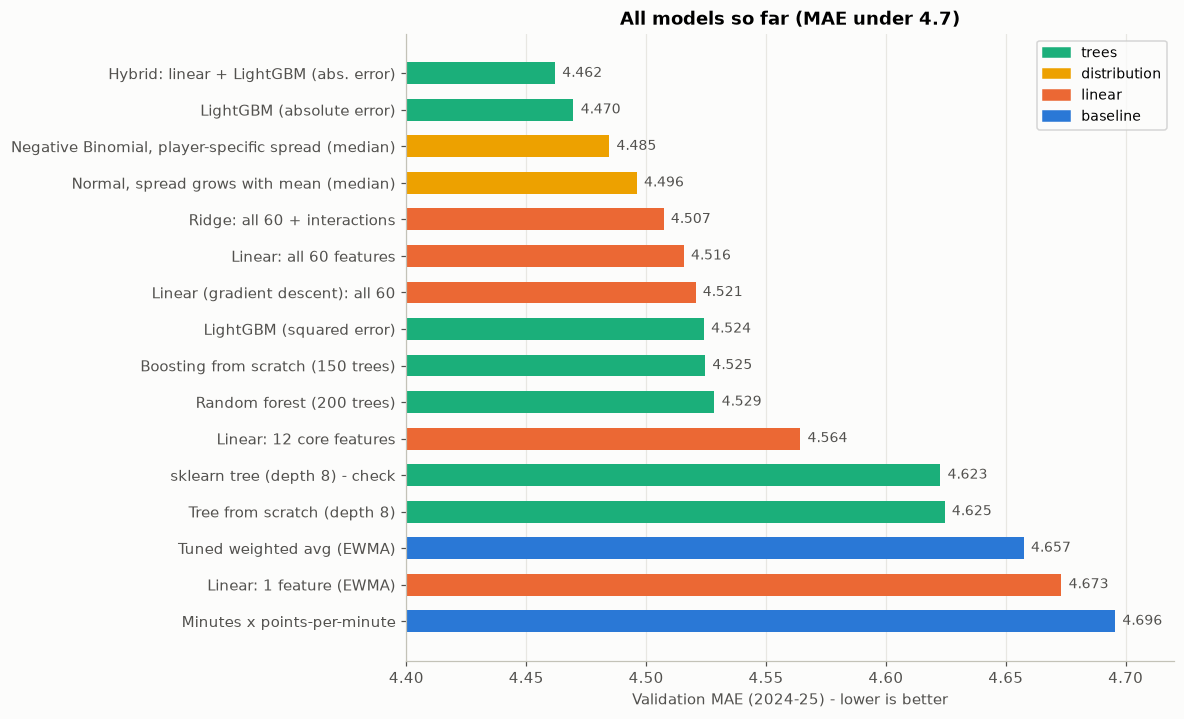

In [8]:
board = pd.read_csv("../results/leaderboard.csv")
board = board[(board["split"] == "valid") & (board["MAE"] < 4.7)].sort_values("MAE", ascending=False)
family = np.select([board["model"].str.contains("LightGBM|tree|Tree|forest|Boosting"),
                    board["model"].str.contains("median"), board["model"].str.contains("Linear|Ridge")],
                   ["trees", "distribution", "linear"], "baseline")
colors = {"trees": AQUA, "distribution": YELLOW, "linear": ORANGE, "baseline": BLUE}
fig, ax = plt.subplots(figsize=(9, 0.4 * len(board) + 1))
ax.barh(board["model"], board["MAE"], color=[colors[f] for f in family], height=0.6)
for i, m in enumerate(board["MAE"]):
    ax.text(m + 0.003, i, f"{m:.3f}", va="center", color=INK_2, fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f) for f, c in colors.items()], loc="upper right", fontsize=9)
ax.set(xlim=(4.4, 4.72), xlabel="Validation MAE (2024-25) - lower is better", title="All models so far (MAE under 4.7)")
ax.grid(axis="y", visible=False)
plt.show()

## 8. Summary

| Model | MAE | Lesson |
|---|---|---|
| One tree, depth 8 (scratch) | 4.624 | Matches scikit-learn (4.623). Crude - piecewise constant |
| Boosting from scratch, 150 trees | 4.525 | Many weak trees >> one strong tree |
| Random forest, 200 trees | 4.529 | Averaging many trees also works |
| LightGBM, squared error | 4.524 | ...but only **ties** linear regression! |
| LightGBM, absolute error | 4.470 | Training on the scoreboard's own metric helps |
| **Hybrid: linear + LightGBM** | **4.462** | Best so far |

**The honest lesson of this phase:** trees did *not* blow linear regression away. Points are mostly a straight-line function of
a player's averages, and trees can only approximate a straight line as a staircase. The "it depends" patterns are real
(teammates-out matters more for stars) but small. The best result came from **combining**: linear regression handles the straight-line part,
trees learn the leftover "it depends" corrections.

Progress so far: **7.05 (blind guess) -> 4.66 (best baseline) -> 4.51 (linear) -> 4.46 (hybrid)**. We're approaching the noise floor -
remember, even stars swing +/-7 points on their own.

**Next (Phase 8): simulation.** Instead of predicting points directly, simulate the game from its parts:
minutes -> shot attempts -> makes. That attacks the weak spots from Phase 6 (0-point games, the exact skew).